# OE2B-02 — Auditoría Yang (para Parte B)

**Dataset:** Smart Bee Colony Monitor — Beehive Sounds (Anna J. Yang, 2017)  
**Fuente:** https://www.kaggle.com/datasets/annajyang/beehive-sounds

## Estructura del dataset

```
<RUTA_YANG>/
  2022-07-15--14-12-51_1_segment0.wav
  2022-07-15--14-12-51_1_segment1.wav
  ...
  2022-07-15--14-12-51_1_segment5.wav   ← 6 segmentos por hora por colmena
  2022-07-15--14-24-58_2_segment0.wav   ← misma hora, colmena 2
  ...
```

**Formato del nombre:** `YYYY-MM-DD--HH-MM-SS_{colmena}_segment{N}.wav`  
- Fecha y hora: en el nombre del archivo  
- Colmena: número después del segundo guion doble  
- Segmento: 0 a 5 (6 archivos de 1 min por hora)

**Etiquetas:** vienen del CSV de Yang (trabajado en OE1), no del nombre del archivo.

## Qué hace este notebook
1. Inventario de archivos (parseo de colmena, timestamp, segmento)
2. Cruce con etiquetas QR/QL del CSV de Yang
3. Verificación de formato (sample rate, canales, bits, duración)
4. Cobertura temporal — ¿qué colmenas tienen datos en qué períodos?
5. Distribución de clases — balance QR/QL por colmena
6. Plan de agregación para xnorC (6 segmentos → 1 representación por hora)
7. Guardar inventario con etiquetas

**Output:** `../data/processed/yang/yang_audio_inventario.csv`  
**No modifica ningún archivo de audio.**

## Configuración

In [4]:
from pathlib import Path

# ─── RUTAS ───────────────────────────────────────────────────────────────────
# Carpeta con todos los archivos .wav de Yang
RUTA_YANG_AUDIO  = Path("/run/media/ikarus/KINGSTON/Tesis-Colmenas/Yang/sound_files")

# CSV de etiquetas de Yang (el que ya usamos en OE1)
# Debe tener al menos: timestamp (o fecha+hora), colmena_id, estado (QR/QL)
RUTA_YANG_LABELS = Path("../data/raw/yang/all_data_updated.csv")

# Salida
RUTA_SALIDA = Path("../data/processed/yang/yang_audio_inventario.csv")

# ─── PARÁMETROS ──────────────────────────────────────────────────────────────
# Duración esperada de cada segmento en segundos (1 minuto exacto)
DURACION_ESPERADA_SEG = 60
TOLERANCIA_SEG        = 5

# Segmentos esperados por hora
SEGMENTOS_POR_HORA = 6
# ─────────────────────────────────────────────────────────────────────────────

RUTA_SALIDA.parent.mkdir(parents=True, exist_ok=True)

print(f"Ruta audio Yang: {RUTA_YANG_AUDIO}")
print(f"Existe:          {RUTA_YANG_AUDIO.exists()}")
print()
print(f"Ruta etiquetas:  {RUTA_YANG_LABELS}")
print(f"Existe:          {RUTA_YANG_LABELS.exists()}")

Ruta audio Yang: /run/media/ikarus/KINGSTON/Tesis-Colmenas/Yang/sound_files
Existe:          True

Ruta etiquetas:  ../data/raw/yang/all_data_updated.csv
Existe:          True


## Importaciones

In [5]:
import pandas as pd
import numpy as np
import wave
import re
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Patch

print("Importaciones listas")

Importaciones listas


---
## 1. Inventario de archivos

Parseamos el nombre de cada archivo para extraer: fecha, hora, colmena y número de segmento.

Formato: `YYYY-MM-DD--HH-MM-SS_{colmena}_segment{N}.wav`

In [6]:
def parsear_nombre_yang(nombre_archivo):
    """
    Parsea el nombre de un archivo de Yang.
    Ejemplo: '2022-07-15--14-12-51_1_segment0.wav'
    Devuelve: (timestamp, colmena_id, segmento) o (NaT, None, None)
    """
    stem = Path(nombre_archivo).stem
    # Formato: YYYY-MM-DD--HH-MM-SS_{colmena}_segment{N}
    m = re.match(
        r'(\d{4})-(\d{2})-(\d{2})--(\d{2})-(\d{2})-(\d{2})_(\d+)__segment(\d+)$',
        stem
    )
    if not m:
        return pd.NaT, None, None

    anio, mes, dia = int(m.group(1)), int(m.group(2)), int(m.group(3))
    hora, min_, seg = int(m.group(4)), int(m.group(5)), int(m.group(6))
    colmena_id = int(m.group(7))
    segmento   = int(m.group(8))

    ts = pd.Timestamp(year=anio, month=mes, day=dia,
                      hour=hora, minute=min_, second=seg)
    return ts, colmena_id, segmento


print("Recorriendo carpeta de audio...")
archivos_wav = sorted(RUTA_YANG_AUDIO.glob('*.wav'))
print(f"Archivos .wav encontrados: {len(archivos_wav):,}")
print()

registros = []
n_error_parseo = 0

for archivo in archivos_wav:
    ts, colmena_id, segmento = parsear_nombre_yang(archivo.name)
    if colmena_id is None:
        n_error_parseo += 1
        continue

    registros.append({
        'colmena_id':  colmena_id,
        'timestamp':   ts,
        'fecha':       ts.date(),
        'hora':        ts.hour,
        'segmento':    segmento,
        'nombre':      archivo.name,
        'ruta':        str(archivo),
        'tamanio_mb':  archivo.stat().st_size / (1024 * 1024),
    })

if n_error_parseo > 0:
    print(f"⚠️  {n_error_parseo} archivos no se pudieron parsear")

df_inv = pd.DataFrame(registros)

print(f"Archivos parseados:  {len(df_inv):,}")
print()
print("Archivos por colmena:")
print(df_inv.groupby('colmena_id').size().rename('n_archivos').to_string())
print()
print("Muestra:")
df_inv.head()

Recorriendo carpeta de audio...
Archivos .wav encontrados: 7,100

Archivos parseados:  7,100

Archivos por colmena:
colmena_id
1    3127
2    3973

Muestra:


,colmena_id,timestamp,fecha,hora,segmento,nombre,ruta,tamanio_mb
0,2,2022-06-05 17:41:01,2022-06-05,17,0,2022-06-05--17-41-01_2__segment0.wav,/run/media/ikarus/KINGSTON/Tesis-Colmenas/Yang...,5.0469
1,2,2022-06-05 17:41:01,2022-06-05,17,1,2022-06-05--17-41-01_2__segment1.wav,/run/media/ikarus/KINGSTON/Tesis-Colmenas/Yang...,5.0469
2,2,2022-06-05 17:41:01,2022-06-05,17,2,2022-06-05--17-41-01_2__segment2.wav,/run/media/ikarus/KINGSTON/Tesis-Colmenas/Yang...,5.0469
3,2,2022-06-05 17:41:01,2022-06-05,17,3,2022-06-05--17-41-01_2__segment3.wav,/run/media/ikarus/KINGSTON/Tesis-Colmenas/Yang...,5.0469
4,2,2022-06-05 17:41:01,2022-06-05,17,4,2022-06-05--17-41-01_2__segment4.wav,/run/media/ikarus/KINGSTON/Tesis-Colmenas/Yang...,5.0469


---
## 2. Cruce con etiquetas QR/QL

Las etiquetas de Yang están en un CSV separado (trabajado en OE1).
Cruzamos por colmena_id + hora para asignar el estado a cada archivo de audio.

**Mapeo de queen_status a QR/QL:**

| queen_status | significado | estado |
|---|---|---|
| 0 | reina original presente | **QR** |
| 1 | sin reina | **QL** |
| 2 | nueva reina rechazada | **QL** |
| 3 | nueva reina aceptada | **QR** |

**Importante:** los 6 segmentos de la misma hora tienen la misma etiqueta.

In [7]:
# Cargar etiquetas
df_labels = pd.read_csv(RUTA_YANG_LABELS)
print(f"Etiquetas cargadas: {len(df_labels):,} filas")
print(f"Columnas: {list(df_labels.columns)}")
print()
print("Muestra:")
df_labels.head()

Etiquetas cargadas: 1,275 filas
Columnas: ['device', 'hive number', 'date', 'hive temp', 'hive humidity', 'hive pressure', 'weather temp', 'weather humidity', 'weather pressure', 'wind speed', 'gust speed', 'weatherID', 'cloud coverage', 'rain', 'lat', 'long', 'file name', 'queen presence', 'queen acceptance', 'frames', 'target', 'time', 'queen status']

Muestra:


,device,hive number,date,hive temp,hive humidity,hive pressure,weather temp,weather humidity,weather pressure,wind speed,...,rain,lat,long,file name,queen presence,queen acceptance,frames,target,time,queen status
0,1,5,2022-06-08 14:52:28,36.42,30.29,1007.45,26.68,52,1013,8.75,...,0,37.29,-121.95,2022-06-08--14-52-28_1.raw,1,2,8,0,0.583,0
1,1,5,2022-06-08 15:51:41,33.56,33.98,1006.93,25.99,53,1012,10.29,...,0,37.29,-121.95,2022-06-08--15-51-41_1.raw,1,2,8,0,0.625,0
2,1,5,2022-06-08 17:21:53,29.01,42.73,1006.68,24.49,56,1012,8.75,...,0,37.29,-121.95,2022-06-08--17-21-53_1.raw,0,0,8,1,0.708,1
3,1,5,2022-06-08 18:20:59,30.51,36.74,1006.68,22.97,59,1012,8.23,...,0,37.29,-121.95,2022-06-08--18-20-59_1.raw,0,0,8,1,0.750,1
4,1,5,2022-06-08 19:20:04,30.32,35.55,1006.58,21.52,61,1012,7.20,...,0,37.29,-121.95,2022-06-08--19-20-04_1.raw,0,0,8,1,0.792,1


In [11]:
# ─── AJUSTAR SEGÚN LAS COLUMNAS REALES DEL CSV ───────────────────────────────
# Revisá los nombres de columna en la celda anterior y ajustá si es necesario

# Nombre de la columna de timestamp en el CSV de etiquetas
COL_TIMESTAMP_LABELS  = 'date'    # ajustar si es distinto
# Nombre de la columna de colmena en el CSV de etiquetas
COL_COLMENA_LABELS    = 'device'      # ajustar si es distinto
# Nombre de la columna queen_status en el CSV de etiquetas
COL_QUEEN_STATUS      = 'queen status' # ajustar si es distinto
# ─────────────────────────────────────────────────────────────────────────────

# Mapeo: queen_status → QR/QL
# 0 = reina original  → QR
# 1 = sin reina       → QL
# 2 = reina rechazada → QL
# 3 = nueva aceptada  → QR
MAPA_QUEEN_STATUS = {0: 'QR', 1: 'QL', 2: 'QL', 3: 'QR'}

# Parsear timestamp del CSV de etiquetas
df_labels['ts_label'] = pd.to_datetime(df_labels[COL_TIMESTAMP_LABELS], errors='coerce')

# Aplicar mapeo queen_status → estado
df_labels['estado'] = df_labels[COL_QUEEN_STATUS].map(MAPA_QUEEN_STATUS)

n_sin_mapa = df_labels['estado'].isna().sum()
if n_sin_mapa > 0:
    print(f"⚠️  {n_sin_mapa} filas del CSV tienen queen_status fuera del rango 0-3")
    print("   Valores únicos encontrados:", df_labels[COL_QUEEN_STATUS].unique())

# Crear clave de unión: colmena + fecha + hora (los 6 segmentos comparten la misma hora)
df_labels['fecha_hora_key'] = (
    df_labels[COL_COLMENA_LABELS].astype(str) + '_' +
    df_labels['ts_label'].dt.date.astype(str) + '_' +
    df_labels['ts_label'].dt.hour.astype(str)
)

df_inv['fecha_hora_key'] = (
    df_inv['colmena_id'].astype(str) + '_' +
    df_inv['fecha'].astype(str) + '_' +
    df_inv['hora'].astype(str)
)

# Mapa de etiquetas: una etiqueta por (colmena, fecha, hora)
mapa_etiquetas = df_labels.set_index('fecha_hora_key')['estado'].to_dict()

df_inv['estado'] = df_inv['fecha_hora_key'].map(mapa_etiquetas)

n_sin_etiqueta = df_inv['estado'].isna().sum()
print(f"Archivos con etiqueta:    {df_inv['estado'].notna().sum():,}")
print(f"Archivos sin etiqueta:    {n_sin_etiqueta:,}")
if n_sin_etiqueta > 0:
    print()
    print("⚠️  Algunos archivos no tienen etiqueta.")
    print("   Puede ser que el CSV no cubra todas las horas del audio.")
    print("   Estos archivos se excluyen del dataset de pares.")

print()
print("Distribución de queen_status en el CSV de etiquetas:")
print(df_labels.groupby([COL_QUEEN_STATUS, 'estado']).size()
      .rename('n_filas').to_string())
print()
print("Distribución QR/QL por colmena (archivos de audio):")
print(df_inv[df_inv['estado'].notna()].groupby(['colmena_id', 'estado']).size()
      .rename('n_archivos').to_string())

Archivos con etiqueta:    7,100
Archivos sin etiqueta:    0

Distribución de queen_status en el CSV de etiquetas:
queen status  estado
0             QR        179
1             QL        158
2             QL        259
3             QR        679

Distribución QR/QL por colmena (archivos de audio):
colmena_id  estado
1           QL        1012
            QR        2115
2           QL        1487
            QR        2486


---
## 3. Verificar formato de audio (muestra)

Leer todos los archivos es lento. Verificamos una muestra de 30 archivos
para confirmar sample rate, canales y duración.

In [13]:
import soundfile as sf   # maneja WAV float32 (formato 3) que wave no soporta

N_MUESTRA = 30
muestra = df_inv.sample(min(N_MUESTRA, len(df_inv)), random_state=42)

formatos = []
for _, fila in muestra.iterrows():
    try:
        info = sf.info(fila['ruta'])
        sr   = info.samplerate
        ch   = info.channels
        dur  = info.duration
        # soundfile no expone bits directamente, lo sacamos del subtipo
        # Ejemplos de subtype: 'PCM_16', 'PCM_24', 'FLOAT', 'DOUBLE'
        sub  = info.subtype   # ej: 'PCM_16', 'FLOAT'
        bit  = sub            # guardamos el string descriptivo
    except Exception as e:
        sr = ch = dur = bit = None
        print(f"⚠️  Error en {fila['nombre']}: {e}")

    formatos.append({'sample_rate': sr, 'canales': ch, 'subtype': bit, 'duracion_seg': dur})

df_fmt = pd.DataFrame(formatos)

print(f"Muestra de {len(df_fmt)} archivos:")
print()
print("Sample rate (Hz):")
print(df_fmt['sample_rate'].value_counts().to_string())
print()
print("Canales:")
print(df_fmt['canales'].value_counts().to_string())
print()
print("Subtipo (formato de muestra):")
print(df_fmt['subtype'].value_counts().to_string())
print()
print("Duración (seg):")
print(df_fmt['duracion_seg'].describe().round(2).to_string())

Muestra de 30 archivos:

Sample rate (Hz):
sample_rate
22050    30

Canales:
canales
1    30

Subtipo (formato de muestra):
subtype
PCM_16    22
FLOAT      8

Duración (seg):
count    30.0
mean     60.0
std       0.0
min      60.0
25%      60.0
50%      60.0
75%      60.0
max      60.0


---
## 4. Cobertura temporal por colmena

¿Qué período cubre cada colmena? ¿Cuándo cambia el estado de QR a QL?

In [14]:
df_etiq = df_inv[df_inv['estado'].notna()].copy()

print("Cobertura por colmena:")
print()
resumen = df_etiq.groupby('colmena_id').agg(
    fecha_inicio = ('fecha', 'min'),
    fecha_fin    = ('fecha', 'max'),
    dias_total   = ('fecha', 'nunique'),
    horas_total  = ('hora',  'count'),  # = n archivos (hay 6 por hora)
    n_QR         = ('estado', lambda x: (x == 'QR').sum()),
    n_QL         = ('estado', lambda x: (x == 'QL').sum()),
).reset_index()
resumen['horas_total'] = resumen['horas_total'] // SEGMENTOS_POR_HORA
print(resumen.to_string(index=False))

Cobertura por colmena:

 colmena_id fecha_inicio  fecha_fin  dias_total  horas_total  n_QR  n_QL
          1   2022-06-08 2022-07-15          28          521  2115  1012
          2   2022-06-05 2022-07-15          33          662  2486  1487


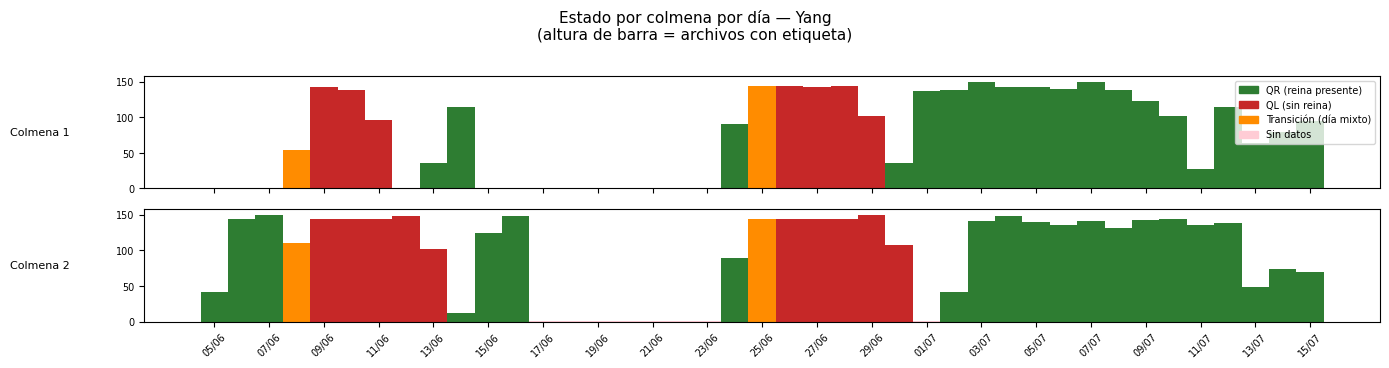

In [15]:
# Gráfico: evolución del estado por colmena a lo largo del tiempo
# Verde = QR, Rojo = QL, por día

colmenas = sorted(df_etiq['colmena_id'].unique())
fecha_min = df_etiq['fecha'].min()
fecha_max = df_etiq['fecha'].max()
todas_fechas = pd.date_range(fecha_min, fecha_max, freq='D').date

n_cols = len(colmenas)
fig, axes = plt.subplots(n_cols, 1,
                          figsize=(max(14, len(todas_fechas) * 0.15), n_cols * 1.8),
                          sharex=True)
if n_cols == 1:
    axes = [axes]

for ax, col_id in zip(axes, colmenas):
    datos_col = df_etiq[df_etiq['colmena_id'] == col_id]
    conteo_dia = datos_col.groupby(['fecha', 'estado']).size().unstack(fill_value=0)

    for i, fecha in enumerate(todas_fechas):
        if fecha not in conteo_dia.index:
            ax.bar(i, 1, color='#FFCCD5', width=1.0, linewidth=0)
        else:
            n_qr = conteo_dia.loc[fecha, 'QR'] if 'QR' in conteo_dia.columns else 0
            n_ql = conteo_dia.loc[fecha, 'QL'] if 'QL' in conteo_dia.columns else 0
            if n_qr > 0 and n_ql == 0:
                color = '#2E7D32'
            elif n_ql > 0 and n_qr == 0:
                color = '#C62828'
            else:
                color = '#FF8C00'  # día mixto (transición)
            ax.bar(i, n_qr + n_ql, color=color, width=1.0, linewidth=0)

    ax.set_ylabel(f"Colmena {col_id}", fontsize=8, rotation=0, labelpad=55, va='center')
    ax.tick_params(axis='y', labelsize=7)

paso = max(1, len(todas_fechas) // 20)
posiciones_x = list(range(0, len(todas_fechas), paso))
axes[-1].set_xticks(posiciones_x)
axes[-1].set_xticklabels(
    [pd.Timestamp(todas_fechas[i]).strftime('%d/%m') for i in posiciones_x],
    rotation=45, fontsize=7
)

leyenda = [
    Patch(color='#2E7D32', label='QR (reina presente)'),
    Patch(color='#C62828', label='QL (sin reina)'),
    Patch(color='#FF8C00', label='Transición (día mixto)'),
    Patch(color='#FFCCD5', label='Sin datos'),
]
axes[0].legend(handles=leyenda, loc='upper right', fontsize=7)

fig.suptitle("Estado por colmena por día — Yang\n(altura de barra = archivos con etiqueta)",
             fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

---
## 5. Balance de clases QR/QL

Para construir el dataset de pares de xnorC necesitamos saber cuántos segmentos
de cada clase hay por colmena. El balance determina cuántos pares IGUAL/DIFERENTE
podemos construir.

In [16]:
print("Balance de clases por colmena (archivos individuales de 1 min):")
print()
balance = df_etiq.groupby(['colmena_id', 'estado']).size().unstack(fill_value=0)
balance['total']     = balance.sum(axis=1)
balance['pct_QR']    = (balance.get('QR', 0) / balance['total'] * 100).round(1)
balance['pct_QL']    = (balance.get('QL', 0) / balance['total'] * 100).round(1)
print(balance.to_string())
print()

# Pares posibles por colmena (estimación)
# Para un par DIFERENTE necesitamos 1 segmento QR y 1 segmento QL
# El máximo de pares DIFERENTE por colmena está limitado por la clase minoritaria
print("Estimación de pares DIFERENTE disponibles por colmena:")
print("(limitado por la clase con menos muestras)")
print()
for col_id in sorted(df_etiq['colmena_id'].unique()):
    datos = df_etiq[df_etiq['colmena_id'] == col_id]
    n_qr = (datos['estado'] == 'QR').sum()
    n_ql = (datos['estado'] == 'QL').sum()
    # Pares DIFERENTE = min(QR, QL) [con balance]
    # Pares IGUAL = idem para mantener balance 50/50
    max_pares = min(n_qr, n_ql)
    print(f"  Colmena {col_id}: {n_qr} QR, {n_ql} QL → hasta {max_pares:,} pares DIFERENTE")
    print(f"               → target xnorC: 500 pares DIFERENTE + 500 pares IGUAL")
    if max_pares < 500:
        print(f"               ⚠️  Menos de 500 — se usarán todos los disponibles")

Balance de clases por colmena (archivos individuales de 1 min):

estado        QL    QR  total  pct_QR  pct_QL
colmena_id                                   
1           1012  2115   3127    67.6    32.4
2           1487  2486   3973    62.6    37.4

Estimación de pares DIFERENTE disponibles por colmena:
(limitado por la clase con menos muestras)

  Colmena 1: 2115 QR, 1012 QL → hasta 1,012 pares DIFERENTE
               → target xnorC: 500 pares DIFERENTE + 500 pares IGUAL
  Colmena 2: 2486 QR, 1487 QL → hasta 1,487 pares DIFERENTE
               → target xnorC: 500 pares DIFERENTE + 500 pares IGUAL


---
## 6. Plan de agregación para xnorC

Yang tiene 6 segmentos de 1 minuto por hora. Para xnorC necesitamos una
representación por unidad temporal comparable con NU-HIVE y UrBAN.

**Estrategia:** extraer features de cada segmento individualmente y luego
promediar las features de los 6 segmentos de la misma hora → 1 vector por hora.

Esto se hace en OE2B-04 (extracción de features). Acá solo verificamos
cuántas horas tienen los 6 segmentos completos.

In [17]:
# Verificar completitud: horas con los 6 segmentos vs. horas incompletas
conteo_por_hora = df_etiq.groupby(['colmena_id', 'fecha', 'hora']).size().reset_index(name='n_seg')

horas_completas   = (conteo_por_hora['n_seg'] == SEGMENTOS_POR_HORA).sum()
horas_incompletas = (conteo_por_hora['n_seg'] <  SEGMENTOS_POR_HORA).sum()

print(f"Horas con los {SEGMENTOS_POR_HORA} segmentos completos: {horas_completas:,}")
print(f"Horas con segmentos faltantes:          {horas_incompletas:,}")
print()

if horas_incompletas > 0:
    print("Distribución de horas incompletas (segmentos disponibles):")
    print(conteo_por_hora[conteo_por_hora['n_seg'] < SEGMENTOS_POR_HORA]
          .groupby('n_seg').size().to_string())
    print()
    print("Decisión: las horas incompletas se incluyen igual, promediando los")
    print("segmentos disponibles (no se descartan por tener menos de 6 segmentos).")

Horas con los 6 segmentos completos: 1,095
Horas con segmentos faltantes:          93

Distribución de horas incompletas (segmentos disponibles):
n_seg
1    17
2    10
3    13
4    11
5    42

Decisión: las horas incompletas se incluyen igual, promediando los
segmentos disponibles (no se descartan por tener menos de 6 segmentos).


---
## 7. Guardar inventario con etiquetas

In [19]:
ORDEN_COLUMNAS = ['colmena_id', 'fecha', 'hora', 'segmento', 'timestamp',
                   'estado', 'nombre', 'ruta', 'tamanio_mb']

cols_finales = [c for c in ORDEN_COLUMNAS if c in df_inv.columns]
df_inv[cols_finales].to_csv(RUTA_SALIDA, index=False)

# Sacar sample rate y subtype del df_fmt generado en la sección 3
sr_modo  = df_fmt['sample_rate'].mode().iloc[0] if 'sample_rate' in df_fmt.columns and not df_fmt.empty else 'ver sección 3'
sub_modo = df_fmt['subtype'].mode().iloc[0]      if 'subtype'     in df_fmt.columns and not df_fmt.empty else 'ver sección 3'

print(f"Inventario guardado en: {RUTA_SALIDA}")
print()
print("=" * 55)
print("RESUMEN FINAL — YANG (audio para OE2-B)")
print("=" * 55)
print(f"  Archivos totales:          {len(df_inv):,}")
print(f"  Archivos con etiqueta:     {df_inv['estado'].notna().sum():,}")
print(f"  Archivos sin etiqueta:     {df_inv['estado'].isna().sum():,}")
print(f"  Colmenas:                  {df_inv['colmena_id'].nunique()}")
print(f"  Período:                   {df_inv['fecha'].min()} → {df_inv['fecha'].max()}")
print(f"  Sample rate (muestra):     {sr_modo} Hz")
print(f"  Subtipo WAV (muestra):     {sub_modo}")
print()
print("─── Estado del preprocesamiento ───")
print(f"  ¿Resampleo a 8 kHz necesario? → verificar resultado sección 3")
print(f"  ¿Conversión a mono necesaria? → verificar resultado sección 3")
print(f"  ¿Normalización float→int16?   → si subtype es FLOAT, sí")
print()
print("─── Próximo paso ───")
print("  OE2B-03: Construcción del dataset de pares (Yang + NU-HIVE)")

Inventario guardado en: ../data/processed/yang/yang_audio_inventario.csv

RESUMEN FINAL — YANG (audio para OE2-B)
  Archivos totales:          7,100
  Archivos con etiqueta:     7,100
  Archivos sin etiqueta:     0
  Colmenas:                  2
  Período:                   2022-06-05 → 2022-07-15
  Sample rate (muestra):     22050 Hz
  Subtipo WAV (muestra):     PCM_16

─── Estado del preprocesamiento ───
  ¿Resampleo a 8 kHz necesario? → verificar resultado sección 3
  ¿Conversión a mono necesaria? → verificar resultado sección 3
  ¿Normalización float→int16?   → si subtype es FLOAT, sí

─── Próximo paso ───
  OE2B-03: Construcción del dataset de pares (Yang + NU-HIVE)
